# Introduction to Machine Learning
## Assignment Section III: 
## Python Data Exercise (46 marks)
**BS Analytics, Semester V · School of Analytics, TISS Mumbai**

**How to use this notebook**
1. Run **every** cell in order, from the top (use *Runtime → Run all* if unsure). Cells marked **PROVIDED** must **NOT** be edited.
2. Cells marked **YOUR CODE HERE** are yours to complete. Written answers go in the markdown cells that follow each task, within the stated word limits (equations and tables do not count toward word limits; explanatory prose does).
3. Before submitting, use *Runtime → Restart session and run all* and confirm that the notebook runs from top to bottom without errors.
4. Enter your **official roll number** exactly once, in Task 0, in the form e.g. `M2024BSASS032` (capital M, no spaces). Do not change the individualization code, the seeds, or the assigned values.
5. Disclose any AI assistance in the declaration cell at the end.


### PROVIDED: Imports (DO NOT CHANGE or EDIT THIS)

In [109]:
import hashlib, json, re, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, roc_auc_score, roc_curve,
                             accuracy_score, precision_score, recall_score, f1_score)


### PROVIDED: Simulated microloan dataset (DO NOT CHANGE or EDIT THIS)
Each row is one microloan made by a (fictional) rural lender. The target `default` is **1** if the borrower missed repayment within 12 months (positive class) and **0** if the loan was repaid (negative class).

| Column | Meaning |
|---|---|
| `age` | Borrower age in years |
| `monthly_income` | Household monthly income (₹); some values are missing |
| `loan_amount` | Loan amount (₹) |
| `term_months` | Loan term (6, 12, 18 or 24 months) |
| `prior_loans` | Number of earlier loans taken from this lender |
| `agri_income_share` | Share of household income from agriculture (0 to 1) |
| `branch_distance_km` | Distance to nearest bank branch (km); some values are missing |
| `savings_group` | 1 if the borrower belongs to a savings group, else 0 |
| `default` | **Target**: 1 = missed repayment (positive), 0 = repaid (negative) |

Kindly note that the data are **simulated**; they are not real borrowers and results do not carry over to real lending.


In [110]:
# Synthetic microloan portfolio dataset generator
# (imports repeated so this cell also works if the import cell above was skipped)
import hashlib, json, re, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, roc_auc_score, roc_curve,
                             accuracy_score, precision_score, recall_score, f1_score)

MASTER_SEED = 20260101
MASTER_N = 3000
TARGET_RATE = 0.20


def make_master_dataset(n=MASTER_N, seed=MASTER_SEED, target_rate=TARGET_RATE):
    """Simulated microloan portfolio. Same output for everyone (fixed seed)."""
    rng = np.random.default_rng(seed)
    age = np.clip(rng.normal(38, 10, n), 21, 65).round()
    income = np.clip(rng.lognormal(np.log(15000), 0.45, n), 4000, 90000).round(-2)
    loan_amount = np.clip(income * rng.uniform(1.0, 4.0, n), 5000, 150000).round(-3)
    term_months = rng.choice([6, 12, 18, 24], size=n, p=[0.2, 0.4, 0.2, 0.2])
    prior_loans = np.clip(rng.poisson(1.5, n), 0, 8)
    agri_share = rng.beta(2, 2.5, n).round(2)
    distance_km = np.clip(rng.gamma(2.0, 4.0, n), 0.5, 40).round(1)
    savings_group = rng.binomial(1, 0.5, n)

    loan_to_income = loan_amount / income
    risk = (1.8 * (loan_to_income - 2.5)
            + 3.0 * (agri_share - 0.4)
            + 0.12 * (distance_km - 8)
            - 2.0 * savings_group
            - 0.60 * (prior_loans - 1.5)
            + 0.50 * (term_months - 12) / 6
            - 0.03 * (age - 38))

    # choose the intercept so that the average default probability equals target_rate
    lo, hi = -10.0, 10.0
    for _ in range(60):
        mid = (lo + hi) / 2
        if (1 / (1 + np.exp(-(mid + risk)))).mean() > target_rate:
            hi = mid
        else:
            lo = mid
    p_default = 1 / (1 + np.exp(-(lo + risk)))
    default = (rng.random(n) < p_default).astype(int)

    df = pd.DataFrame({
        "age": age,
        "monthly_income": income,
        "loan_amount": loan_amount,
        "term_months": term_months,
        "prior_loans": prior_loans,
        "agri_income_share": agri_share,
        "branch_distance_km": distance_km,
        "savings_group": savings_group,
        "default": default,
    })
    # a few values are missing (realistic data entry gaps)
    df.loc[rng.random(n) < 0.03, "monthly_income"] = np.nan
    df.loc[rng.random(n) < 0.02, "branch_distance_km"] = np.nan
    return df


def master_checksum(df):
    return hashlib.sha256(df.round(4).to_csv(index=True).encode("utf-8")).hexdigest()[:16].upper()


EXPECTED_MASTER_CHECKSUM = "2AFAEA208FCBF28D"   # reference value (you should not change this value)


### PROVIDED: Individualization functions (DO NOT CHANGE or EDIT THIS)
Your roll number is turned into a number (a *seed*) using SHA-256, which gives the same answer on every system and every run. 

The seed then decides 

**1.** which 900 loans from the master dataset you receive (always exactly 180 defaults and 720 repaid), 

**2.** your train/test split (80%/20%, stratified), and 

**3.** your assigned **K** for KNN and assigned **maximum depth** for the decision tree.


In [111]:
# (imports repeated so this cell also works if the import cell above was skipped)
import hashlib, json, re, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, roc_auc_score, roc_curve,
                             accuracy_score, precision_score, recall_score, f1_score)

COURSE_SALT = "TISS-BSA-IML-2026"
K_OPTIONS = [3, 5, 7, 9, 11]
DEPTH_OPTIONS = [4, 5, 6, 7]
N_SAMPLE, N_POS = 900, 180
TEST_SIZE = 0.20


def normalise_roll(raw):
    roll = re.sub(r"[^0-9A-Za-z]", "", str(raw)).upper()   # drop spaces/separators, use capitals
    if len(roll) < 3:
        raise ValueError("Roll number looks too short. Please enter your official roll number.")
    if not re.fullmatch(r"M\d{4}[A-Z]+\d{3}", roll):
        print("NOTE: expected a roll number like M2024BSASS032; you entered", roll,
              "- please check it before continuing.")
    return roll


def make_assignment(roll, master):
    """Deterministic mapping: roll number -> seed, K, depth, sample, split."""
    digest = hashlib.sha256((COURSE_SALT + "|" + roll).encode("utf-8")).digest()
    seed = int.from_bytes(digest[:4], "big")
    k = K_OPTIONS[digest[4] % len(K_OPTIONS)]
    depth = DEPTH_OPTIONS[digest[5] % len(DEPTH_OPTIONS)]

    rng = np.random.default_rng(seed)
    pos_ids = master.index[master["default"] == 1].to_numpy()
    neg_ids = master.index[master["default"] == 0].to_numpy()
    chosen = np.concatenate([rng.choice(pos_ids, N_POS, replace=False),
                             rng.choice(neg_ids, N_SAMPLE - N_POS, replace=False)])
    rng.shuffle(chosen)
    data = master.loc[chosen]            # the index keeps the master row id

    X = data.drop(columns="default")
    y = data["default"]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, stratify=y, random_state=seed)

    # inner validation split (taken from the TRAINING part only) for choosing K, depth etc.
    X_fit, X_val, y_fit, y_val = train_test_split(
        X_train, y_train, test_size=0.20, stratify=y_train, random_state=(seed + 1) % (2 ** 32))

    version_id = hashlib.sha256(
        (roll + "|" + ",".join(map(str, sorted(chosen)))).encode("utf-8")).hexdigest()[:10].upper()
    return dict(seed=seed, k=k, depth=depth, version_id=version_id, student_data=data,
                X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test,
                X_fit=X_fit, X_val=X_val, y_fit=y_fit, y_val=y_val)


## Task 0: Setup and individualization (4 marks)

In [112]:
# PROVIDED: run once. Enter your official roll number when asked. (2 marks) 
roll_raw = input("Enter your official roll number: ")
ROLL = normalise_roll(roll_raw)

master = make_master_dataset()
MASTER_CHECK = master_checksum(master)
if MASTER_CHECK != EXPECTED_MASTER_CHECKSUM:
    warnings.warn("Master dataset checksum differs from the reference value. "
                  "Your library versions may differ; tell your instructor and include this warning in your submission.")

assignment = make_assignment(ROLL, master)
SEED, K_ASSIGNED, DEPTH_ASSIGNED = assignment["seed"], assignment["k"], assignment["depth"]
VERSION_ID = assignment["version_id"]
student_data = assignment["student_data"] # do not confuse with this name. this data represents microloan. Each student will have a different sample of the master dataset, but the same master dataset is used for everyone.
X_train, X_test = assignment["X_train"], assignment["X_test"]
y_train, y_test = assignment["y_train"], assignment["y_test"]
X_fit, X_val = assignment["X_fit"], assignment["X_val"]
y_fit, y_val = assignment["y_fit"], assignment["y_val"]

# edge-case checks: both classes present, enough positives for meaningful evaluation
assert y_train.nunique() == 2 and y_test.nunique() == 2, "A split contains only one class."
assert y_train.sum() >= 100 and y_test.sum() >= 30, "Too few positive cases."

config = dict(roll_number=ROLL, seed=SEED, assigned_k=K_ASSIGNED, assigned_max_depth=DEPTH_ASSIGNED,
              version_id=VERSION_ID, n_total=len(student_data), n_train=len(X_train), n_test=len(X_test),
              test_positives=int(y_test.sum()), master_checksum=MASTER_CHECK,
              python_libs=dict(numpy=np.__version__, pandas=pd.__version__, sklearn=sklearn.__version__))
with open("assignment_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("Roll number (normalised):", ROLL)
print("VERSION ID:", VERSION_ID, "   <-- copy this into your submission")
print("Assigned K (KNN):", K_ASSIGNED, "| Assigned max depth (tree):", DEPTH_ASSIGNED)
print("Rows:", len(student_data), "| train:", len(X_train), "| test:", len(X_test),
      "| test positives:", int(y_test.sum()))
print("Saved assignment_config.json (submit this file with your notebook).")

Roll number (normalised): M2024BSASS027
VERSION ID: 20AA1102C3    <-- copy this into your submission
Assigned K (KNN): 9 | Assigned max depth (tree): 4
Rows: 900 | train: 720 | test: 180 | test positives: 36
Saved assignment_config.json (submit this file with your notebook).


**Task 0 written answer (2 marks).** In your own words, explain one thing this individualization does *not* guarantee (for example, that two students will get completely different results).

**Your answer (maximum 100 words):**

_By using this indivisualisation a representative sample is not guaranteed, means a random draw of 900 can by chance be unusual and with just 36 test defaulters results can swing._

In [113]:
# exploration for my reference
student_data.head(10)

,age,monthly_income,loan_amount,term_months,prior_loans,agri_income_share,branch_distance_km,savings_group,default
296,21.0,13200.0,20000.0,12,2,0.29,3.9,0,0
313,22.0,12000.0,40000.0,6,2,0.49,10.8,0,0
2607,50.0,NaN,25000.0,12,2,0.22,8.0,1,0
2406,24.0,15400.0,22000.0,6,0,0.69,3.6,0,0
2042,26.0,18500.0,48000.0,18,1,0.33,2.0,0,0
1208,33.0,12800.0,24000.0,6,0,0.26,14.4,1,0
2980,32.0,NaN,85000.0,12,2,0.76,3.9,0,1
2253,42.0,19000.0,25000.0,12,1,0.62,3.0,0,0
2683,46.0,44100.0,145000.0,6,0,0.50,4.1,1,0
1043,65.0,18700.0,74000.0,12,1,0.46,5.7,1,0


## Task 1 Data inspection (5 marks)
**1.1** *(3 marks, Python)* For `student_data`, display the shape, the data types, the class counts and proportions of `default`, summary statistics, and the number of missing values per column. 

**1.2** include at least **two** plots (for example, a bar chart of class counts and histograms of `monthly_income` and `branch_distance_km`).

1. shape: (900, 9) 

2. dtypes:
 age                   float64
monthly_income        float64
loan_amount           float64
term_months             int64
prior_loans             int64
agri_income_share     float64
branch_distance_km    float64
savings_group           int64
default                 int64
dtype: object 

3. class counts and proportions:
 default
0    0.8
1    0.2
Name: proportion, dtype: float64 

4. summary statistics:
           age  monthly_income  loan_amount  term_months  prior_loans  \
count  900.00          872.00       900.00       900.00       900.00   
mean    38.32        16227.87     41458.89        14.47         1.47   
std      9.64         7864.41     26487.55         6.11         1.22   
min     21.00         4000.00      5000.00         6.00         0.00   
25%     32.00        10800.00     23000.00        12.00         1.00   
50%     38.00        14700.00     35000.00        12.00         1.00   
75%     44.25        19800.00     52000.00        18.00   

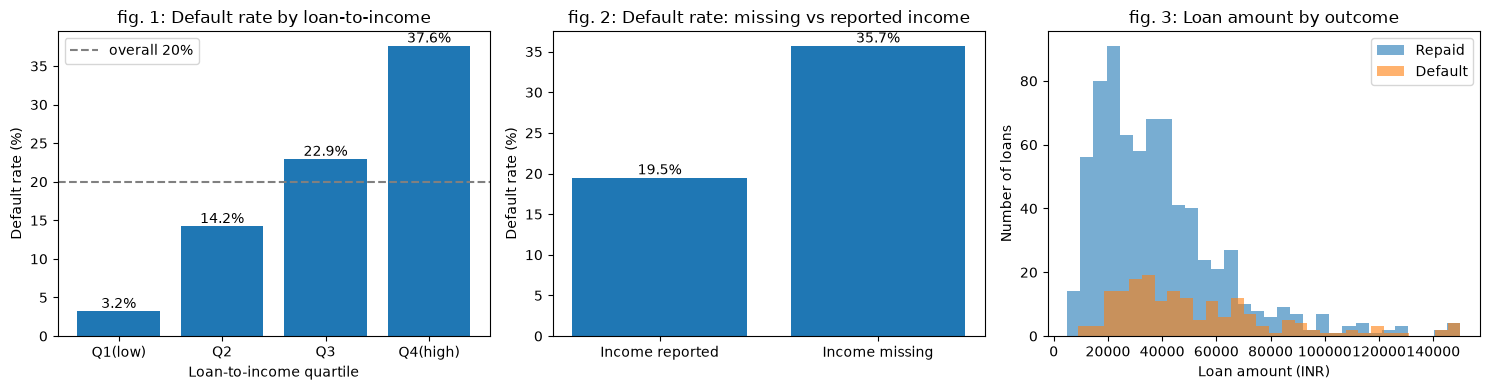

In [114]:
# TASK 1 YOUR CODE HERE
# 1.1 shape, dtypes, class counts and proportions, summary statistics, missing values per column
print('1. shape:',student_data.shape,'\n')
print('2. dtypes:\n',student_data.dtypes,'\n')
print('3. class counts and proportions:\n',student_data['default'].value_counts(normalize=True).round(3),'\n')
print('4. summary statistics:\n',student_data.describe().round(2),'\n')
print('5. missing values per column:\n',student_data.isna().sum(),'\n')

# 1.2 at least two plots
counts = student_data["default"].value_counts().sort_index()

d = student_data.copy()
d["loan_to_income"] = d["loan_amount"] / d["monthly_income"]

plt.figure(figsize=(15, 4))

# Plot 1: default rate by loan-to-income quartile
plt.subplot(1, 3, 1)
lti_rate = d.groupby(pd.qcut(d["loan_to_income"], 4, labels=["Q1(low)", "Q2", "Q3", "Q4(high)"]), observed=True)["default"].mean() * 100
bars = plt.bar(lti_rate.index, lti_rate.values)
plt.bar_label(bars, fmt="%.1f%%")
plt.axhline(d["default"].mean() * 100, color="grey", linestyle="--", label="overall 20%")
plt.title("fig. 1: Default rate by loan-to-income")
plt.xlabel("Loan-to-income quartile")
plt.ylabel("Default rate (%)")
plt.legend()

# Plot 2: default rate when income is missing vs reported
plt.subplot(1, 3, 2)
miss_rate = d.groupby(d["monthly_income"].isna())["default"].mean() * 100
bars = plt.bar(["Income reported", "Income missing"], miss_rate.values)
plt.bar_label(bars, fmt="%.1f%%")
plt.title("fig. 2: Default rate: missing vs reported income")
plt.ylabel("Default rate (%)")

# Plot 3: loan amount by outcome (right-skewed, defaulters borrow more)
plt.subplot(1, 3, 3)
plt.hist(d[d["default"] == 0]["loan_amount"], bins=30, alpha=0.6, label="Repaid")
plt.hist(d[d["default"] == 1]["loan_amount"], bins=30, alpha=0.6, label="Default")
plt.title("fig. 3: Loan amount by outcome")
plt.xlabel("Loan amount (INR)")
plt.ylabel("Number of loans")
plt.legend()

plt.tight_layout()
plt.show()


**Task 1 written answer (2 marks).** State three observations from your inspection that will matter for modelling (for example about class balance, differences in feature scales, or missing values), and say why each matters.

**Your answer (maximum 150 words):**

_The three observations are:_
1. *Loan size relative to income matters more than income because he default rate rises from 3.2% in the lowest loan-to-income quartile to 37.6% in the highest (fig. 1). The models only see income and loan amount as separate columns, so they have to learn this relationship indirectly.*

2. *Missing income signals higher risk as borrowers with missing income default at 35.7%, against 19.5% for those who reported it (fig. 2). Filling these gaps with the median makes them look average and hides this signal.*

3. *Loan amounts are right-skewed (fig. 3). Most loans are small, with a long tail of large ones. That's why the median, not the mean, is used to fill gaps, and why scaling is needed before KNN, SVM and logistic regression.*


## Task 2 Preparation, split and scaling without leakage (6 marks)
Your train/test split (80%/20%, stratified) and a smaller validation split taken **from the training part only** (`X_fit`, `X_val`) were created for you in Task 0. The **test set must not be used to make any modelling choice.**

Write a function `prepare_features(X_fit, X_apply)` that:

2.1 computes the **median of each column from `X_fit` only** and uses it to fill missing values in both `X_fit` and `X_apply` *(2 marks)*;

2.2 fits a `StandardScaler` on the **imputed `X_fit` only** and uses it to scale both *(2 marks)*;

2.3 returns four objects: imputed `X_fit`, imputed `X_apply`, scaled `X_fit`, scaled `X_apply`.

Then call it for (`X_train`, `X_test`) and for (`X_fit`, `X_val`).

In [115]:
# TASK 2 YOUR CODE HERE
def prepare_features(X_fit, X_apply):
    # fill missing values using medians computed on X_fit only
    medians = X_fit.median()
    fit_imp = X_fit.fillna(medians)
    apply_imp = X_apply.fillna(medians)

    # fit the scaler on the imputed X_fit only
    scaler = StandardScaler().set_output(transform='pandas')
    fit_sc = scaler.fit_transform(fit_imp)
    apply_sc = scaler.transform(apply_imp)

    # return fit_imp, apply_imp, fit_sc, apply_sc
    return fit_imp, apply_imp, fit_sc, apply_sc

# final-model data:  Xtr_imp, Xte_imp, Xtr_sc, Xte_sc = prepare_features(X_train, X_test)
Xtr_imp, Xte_imp, Xtr_sc, Xte_sc = prepare_features(X_train, X_test)

# validation data:   Xfit_imp, Xval_imp, Xfit_sc, Xval_sc = prepare_features(X_fit, X_val)
Xfit_imp, Xval_imp, Xfit_sc, Xval_sc = prepare_features(X_fit, X_val)

# checks: no missing values remain; scaled training columns have mean about 0 and std about 1
print('Missing after imputation:','\n',
        'Train:',Xtr_imp.isna().sum().sum(),
        'Test:',Xte_imp.isna().sum().sum(),
        'Fit:',Xfit_imp.isna().sum().sum(),
        'Val:',Xval_imp.isna().sum().sum(), '\n')

print('Scaled training columns, mean (about 0):','\n', 
        Xtr_sc.mean().round(3), '\n')
print('Scaled training columns, std (about 1):','\n',
        Xtr_sc.std(ddof=0).round(3))

Missing after imputation: 
 Train: 0 Test: 0 Fit: 0 Val: 0 

Scaled training columns, mean (about 0): 
 age                   0.0
monthly_income        0.0
loan_amount           0.0
term_months           0.0
prior_loans          -0.0
agri_income_share     0.0
branch_distance_km   -0.0
savings_group         0.0
dtype: float64 

Scaled training columns, std (about 1): 
 age                   1.0
monthly_income        1.0
loan_amount           1.0
term_months           1.0
prior_loans           1.0
agri_income_share     1.0
branch_distance_km    1.0
savings_group         1.0
dtype: float64


**Task 2 written answer (2 marks).** Explain what *data leakage* would occur if you computed the medians or the scaling parameters on the full dataset (train + test), and why that makes test results less trustworthy.

**Your answer (maximum 120 words):**

_*If the medians, means and standard deviations were computed on train and test together, information from the test set would flow into the training data before the model is evaluated. The test set is meant to act like future borrowers the model has never seen. Once its values have shaped the preprocessing, it is no longer truly unseen. The test score would then be optimistically biased and would overstate how well the model works on real new applicants.*_

In [116]:
# summary of the eight prepared tables for my reference (not part of the assignment, but useful for debugging)
summary = pd.DataFrame({
    "Variable": ["Xtr_imp", "Xte_imp", "Xtr_sc", "Xte_sc", "Xfit_imp", "Xval_imp", "Xfit_sc", "Xval_sc"],
    "Rows":     [len(Xtr_imp), len(Xte_imp), len(Xtr_sc), len(Xte_sc), len(Xfit_imp), len(Xval_imp), len(Xfit_sc), len(Xval_sc)],
    "Loans":    ["training", "test", "training", "test", "fit", "validation", "fit", "validation"],
    "Processing": ["imputed", "imputed", "imputed + scaled", "imputed + scaled", "imputed", "imputed", "imputed + scaled", "imputed + scaled"],
    "Learned from": ["X_train", "X_train", "X_train", "X_train", "X_fit", "X_fit", "X_fit", "X_fit"],
    "Missing values": [Xtr_imp.isna().sum().sum(), Xte_imp.isna().sum().sum(), Xtr_sc.isna().sum().sum(), Xte_sc.isna().sum().sum(),
                         Xfit_imp.isna().sum().sum(), Xval_imp.isna().sum().sum(), Xfit_sc.isna().sum().sum(), Xval_sc.isna().sum().sum()],
})

summary

,Variable,Rows,Loans,Processing,Learned from,Missing values
0,Xtr_imp,720,training,imputed,X_train,0
1,Xte_imp,180,test,imputed,X_train,0
2,Xtr_sc,720,training,imputed + scaled,X_train,0
3,Xte_sc,180,test,imputed + scaled,X_train,0
4,Xfit_imp,576,fit,imputed,X_fit,0
5,Xval_imp,144,validation,imputed,X_fit,0
6,Xfit_sc,576,fit,imputed + scaled,X_fit,0
7,Xval_sc,144,validation,imputed + scaled,X_fit,0


## Task 3 Baseline (3 marks)
Create a **majority-class baseline** with `DummyClassifier(strategy="most_frequent")`, fitted on the training data. Report its confusion matrix on the test set, its accuracy and its recall for the positive class *(1 mark)*.

refer to DummyClassifier in scikit learn documentation. 

In [117]:
# TASK 3 YOUR CODE HERE
baseline = DummyClassifier(strategy="most_frequent")   # create the "always guess the majority" model
baseline.fit(Xtr_imp, y_train)                         # learn: majority class in training = 0
y_pred_base = baseline.predict(Xte_imp)                # apply: predicts 0 for all 180 test loans

print("Confusion matrix (rows = actual 0/1, columns = predicted 0/1):",'\n',confusion_matrix(y_test, y_pred_base))
print("Accuracy:", accuracy_score(y_test, y_pred_base))
print("Recall (default = 1):", recall_score(y_test, y_pred_base))

Confusion matrix (rows = actual 0/1, columns = predicted 0/1): 
 [[144   0]
 [ 36   0]]
Accuracy: 0.8
Recall (default = 1): 0.0


**Task 3 written answer (2 marks).** Why is a baseline useful? What do the baseline's accuracy and recall tell you about judging models on this dataset?

**Your answer (maximum 100 words):**

_*A baseline shows the score a model gets without learning anything, so every real model must beat it. Our baseline always predicts "repaid" and still reaches 0.80 accuracy, because 80% of loans are repaid. But its recall is 0.0: it catches none of the 36 defaulters, the group the lender cares about most. So accuracy alone is misleading on this imbalanced data, and models should be judged on recall, precision, F1 and ROC-AUC.*
._

## Task 4 Model building (8 marks)
Use the **assigned** `K_ASSIGNED` and `DEPTH_ASSIGNED`. Fit on the **training data** only.

| Model | Settings | Input to use |
|---|---|---|
| Logistic regression | `max_iter=1000` | scaled |
| KNN | `n_neighbors=K_ASSIGNED` | scaled |
| Gaussian Naive Bayes | defaults | imputed (unscaled) |
| Decision tree | `criterion="entropy"`, `max_depth=DEPTH_ASSIGNED`, `random_state=SEED` | imputed (unscaled) |
| Linear SVM | `SVC(kernel="linear", C=1.0)` | scaled |

**4.1** Fit the five models *(4 marks)*. 

**4.2** *(2 marks)* Using the **validation split** (not the test set), compare KNN with `K_ASSIGNED` on **scaled** versus **unscaled** inputs (accuracy and recall on `X_val`) and explain in words what you see. 

**4.3** *(2 marks)* Print the rules of your decision tree with `export_text`, and explain the **root split** using the idea of **information gain**.

In [118]:
# TASK 4 YOUR CODE HERE

# 4.1 fit the five models
lr   = LogisticRegression(max_iter=1000)
knn  = KNeighborsClassifier(n_neighbors=K_ASSIGNED)
nb   = GaussianNB()
tree = DecisionTreeClassifier(criterion="entropy", max_depth=DEPTH_ASSIGNED, random_state=SEED)
svm  = SVC(kernel="linear", C=1.0)

lr.fit(Xtr_sc, y_train)     
knn.fit(Xtr_sc, y_train)
nb.fit(Xtr_imp, y_train)
tree.fit(Xtr_imp, y_train)
svm.fit(Xtr_sc, y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [119]:
# 4.2 KNN on validation data: scaled vs unscaled inputs
knn_sc = KNeighborsClassifier(n_neighbors=K_ASSIGNED).fit(Xfit_sc, y_fit)
knn_un = KNeighborsClassifier(n_neighbors=K_ASSIGNED).fit(Xfit_imp, y_fit)

pred_sc = knn_sc.predict(Xval_sc)
pred_un = knn_un.predict(Xval_imp)

knn_compare = pd.DataFrame({
    "Accuracy": [accuracy_score(y_val, pred_sc), accuracy_score(y_val, pred_un)],
    "Recall":   [recall_score(y_val, pred_sc),   recall_score(y_val, pred_un)],
}, index=["KNN scaled", "KNN unscaled"]).round(4)
knn_compare

,Accuracy,Recall
KNN scaled,0.8056,0.2069
KNN unscaled,0.7917,0.0690


In [120]:
# 4.3 print the tree rules
pr = export_text(tree, feature_names=list(Xtr_imp.columns))
print(pr)

|--- savings_group <= 0.50
|   |--- loan_amount <= 24500.00
|   |   |--- branch_distance_km <= 18.25
|   |   |   |--- monthly_income <= 4450.00
|   |   |   |   |--- class: 1
|   |   |   |--- monthly_income >  4450.00
|   |   |   |   |--- class: 0
|   |   |--- branch_distance_km >  18.25
|   |   |   |--- monthly_income <= 10850.00
|   |   |   |   |--- class: 1
|   |   |   |--- monthly_income >  10850.00
|   |   |   |   |--- class: 0
|   |--- loan_amount >  24500.00
|   |   |--- monthly_income <= 13150.00
|   |   |   |--- agri_income_share <= 0.41
|   |   |   |   |--- class: 0
|   |   |   |--- agri_income_share >  0.41
|   |   |   |   |--- class: 1
|   |   |--- monthly_income >  13150.00
|   |   |   |--- loan_amount <= 65500.00
|   |   |   |   |--- class: 0
|   |   |   |--- loan_amount >  65500.00
|   |   |   |   |--- class: 1
|--- savings_group >  0.50
|   |--- branch_distance_km <= 8.05
|   |   |--- agri_income_share <= 0.62
|   |   |   |--- class: 0
|   |   |--- agri_income_share >  0

**Task 4 written answers.**

**4.2** What do you observe, and why does feature scaling matter for KNN? *(maximum 100 words)*

_Scaling clearly helps KNN as Recall rises from 0.069 (unscaled) to 0.2069 (scaled), while accuracy barely changes (0.7917 to 0.8056) and stays close to the baseline. KNN predicts using distances to the nearest borrowers. Without scaling, large-number features like loan amount and income dominate the distance, and small-range features like savings group or agricultural income share are almost ignored. Scaling puts all features on the same footing, so every feature counts._

**4.3** Which feature does the tree split on first? Explain, in terms of information gain (reduction in entropy), why a split like this is chosen. *(maximum 100 words)*

_The tree splits first on savings group i.e. members versus non-members._ 

_So entropy here basically measures how mixed a group is between defaulters and repayers. At every node, the tree tries each feature and threshold and picks the split that reduces entropy the most, which is the highest information gain. Savings group was chosen because it separates defaulters from repayers better than any other single question, leaving purer groups after the split._

## Task 5 Parameter reasoning (6 marks)
All comparisons in this task use the **training/validation split only** (`Xfit_*`, `Xval_*`), never the test set. Use **F1-score for the positive class** as the measure.

**5.1 K in KNN** *(2 marks)*: for K in `[1, 3, 5, 7, 9, 11, 15, 21, 31]`, fit KNN on the scaled fit data, compute F1 on the fit data and on the validation data, and plot both against K.

**5.2 Depth of the tree** *(2 marks)*: for `max_depth` from 1 to 10 (`criterion="entropy"`), do the same on the imputed data.

**5.3 Regularization C in a linear SVM** *(2 marks)*: for C in `[0.01, 1, 100]`, fit `SVC(kernel="linear", C=C)` on the **scaled training data** (`Xtr_sc`) and report the total number of support vectors (`model.n_support_.sum()`).

    K  fit F1  val F1
0   1  1.0000  0.3774
1   3  0.7100  0.4583
2   5  0.5803  0.3111
3   7  0.5465  0.2857
4   9  0.4819  0.3000
5  11  0.4224  0.3721
6  15  0.3151  0.4000
7  21  0.3099  0.2778
8  31  0.1260  0.1765


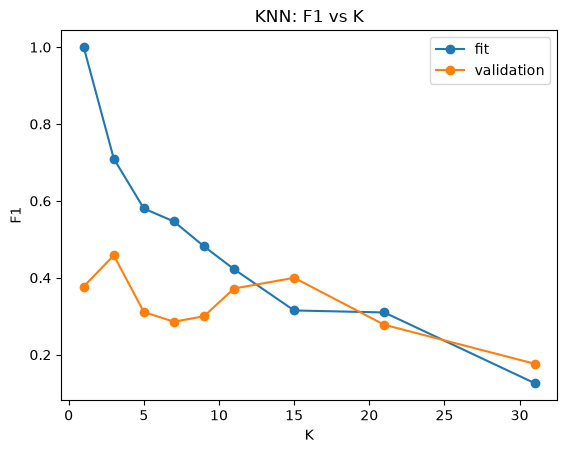

In [121]:
# TASK 5 YOUR CODE HERE
K_GRID = [1, 3, 5, 7, 9, 11, 15, 21, 31]
DEPTH_GRID = list(range(1, 11))
C_GRID = [0.01, 1, 100]

# 5.1 KNN sweep + plot
fit_f1 = []
val_f1 = []
for k in K_GRID:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(Xfit_sc, y_fit)
    fit_f1.append(f1_score(y_fit, model.predict(Xfit_sc)))
    val_f1.append(f1_score(y_val, model.predict(Xval_sc)))

print(pd.DataFrame({"K": K_GRID, "fit F1": fit_f1, "val F1": val_f1}).round(4))

plt.plot(K_GRID, fit_f1, marker="o", label="fit")
plt.plot(K_GRID, val_f1, marker="o", label="validation")
plt.xlabel("K")
plt.ylabel("F1")
plt.title("KNN: F1 vs K")
plt.legend()
plt.show()

   depth  fit F1  val F1
0      1  0.0000  0.0000
1      2  0.2406  0.0000
2      3  0.2406  0.0000
3      4  0.2308  0.0000
4      5  0.6030  0.4706
5      6  0.7117  0.5714
6      7  0.7461  0.2222
7      8  0.8060  0.2979
8      9  0.8762  0.2917
9     10  0.9100  0.3396


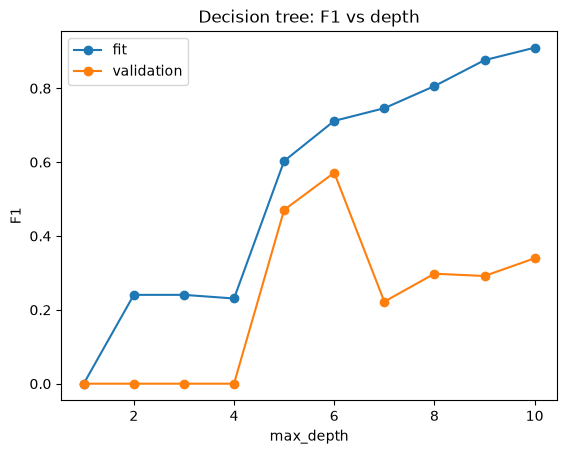

In [122]:
# 5.2 tree depth sweep + plot
fit_f1 = []
val_f1 = []
for d in DEPTH_GRID:
    model = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=SEED)
    model.fit(Xfit_imp, y_fit)
    fit_f1.append(f1_score(y_fit, model.predict(Xfit_imp)))
    val_f1.append(f1_score(y_val, model.predict(Xval_imp)))

print(pd.DataFrame({"depth": DEPTH_GRID, "fit F1": fit_f1, "val F1": val_f1}).round(4))

plt.plot(DEPTH_GRID, fit_f1, marker="o", label="fit")
plt.plot(DEPTH_GRID, val_f1, marker="o", label="validation")
plt.xlabel("max_depth")
plt.ylabel("F1")
plt.title("Decision tree: F1 vs depth")
plt.legend()
plt.show()

In [123]:
# 5.3 SVM support vectors for each C
sv_counts = []
for C in C_GRID:
    m = SVC(kernel="linear", C=C).fit(Xtr_sc, y_train)
    sv_counts.append(m.n_support_.sum())
svm_table = pd.DataFrame({"C": C_GRID, "support vectors": sv_counts})
svm_table

,C,support vectors
0,0.01,291
1,1.00,255
2,100.00,250


**Task 5 written answers.**

**5.1** Describe how fit F1 and validation F1 change as K increases, and what this says about small and large K. *(maximum 120 words)*

_Fit F1 falls steadily as K increases, from 1.0 at K = 1 to 0.126 at K = 31. At K = 1 the model overfits: each fit point is its own nearest neighbour, so it scores perfectly on fit data but only 0.3774 on validation._ 

_As K grows the model gets smoother. At large K it underfits: with only 20% defaulters, most neighbourhoods vote "repaid", so both scores drop. Validation F1 is noisy because the validation set has few defaulters. It is highest at K = 3 (0.4583)._

**5.2** Describe how fit and validation F1 change with depth, and where overfitting begins to appear. Comment on whether your assigned depth looks reasonable. *(maximum 120 words)*

_Fit F1 rises steadily with depth, from 0 at depth 1 to 0.91 at depth 10. Validation F1 is 0 up to depth 4, so these shallow trees underfit and predict no defaulters. It peaks at depth 6 (0.5714). From depth 7 onward, fit F1 keeps rising while validation F1 drops to about 0.22 to 0.34. This is where overfitting begins._ 

_On this split my assigned depth of 4 looks too shallow so it getting a depth of 5 or 6 would have been more reasonable._

**5.3** How does the number of support vectors change with C, and what does this say about the margin and about regularization? *(maximum 100 words)*

_The number of support vectors falls as C increases: 291 at C = 0.01, 255 at C = 1 and 250 at C = 100._ 

_A small C tolerates margin violations, which gives a wider margin with more points on or inside it, so there are more support vectors and stronger regularization. A large C penalizes violations heavily, which gives a narrower margin, fewer support vectors and weaker regularization, with more risk of overfitting. The small change from 1 to 100 suggests the classes overlap a lot._

## Task 6 Evaluation (8 marks)

**6.1** *(2 marks)* For the baseline and all five models, compute the confusion matrix on the **test set** using each model's default decision rule.

**6.2** *(2 marks)* Write your own function `metrics_from_cm(tn, fp, fn, tp)` that returns accuracy, precision, recall, specificity and F1 **from the four counts** (using formulas, not sklearn's metric functions). If a denominator is zero, return `0.0` for that metric. Check your function against sklearn for at least one model.

**6.3** *(2 marks)* Compute **ROC-AUC from scores, not from class labels**: `predict_proba(...)[:, 1]` for LR, KNN, Naive Bayes and the tree, and `decision_function(...)` for the linear SVM. Plot the ROC curves of the five models on one figure.

**6.4** *(2 marks)* Present one table with all six rows (baseline + five models) and the six metrics (accuracy, precision, recall, specificity, F1, ROC-AUC).

Model: baseline, TN: 144, FP: 0, FN: 36, TP: 0
Model: logistic, TN: 133, FP: 11, FN: 18, TP: 18
Model: knn, TN: 134, FP: 10, FN: 28, TP: 8
Model: naive_bayes, TN: 130, FP: 14, FN: 29, TP: 7
Model: decision_tree, TN: 129, FP: 15, FN: 22, TP: 14
Model: svm, TN: 136, FP: 8, FN: 19, TP: 17

my precision: 0.6207  sklearn: 0.6207
my recall: 0.5  sklearn: 0.5
my f1: 0.5538  sklearn: 0.5538


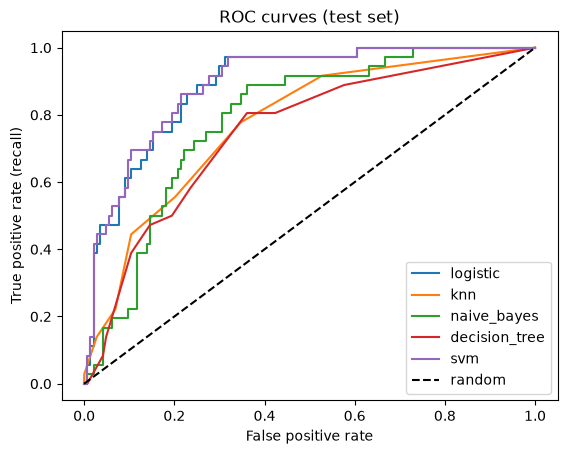

,accuracy,precision,recall,specificity,f1,roc_auc
model,,,,,,
baseline,0.8000,0.0000,0.0000,1.0000,0.0000,0.5000
logistic,0.8389,0.6207,0.5000,0.9236,0.5538,0.8877
knn,0.7889,0.4444,0.2222,0.9306,0.2963,0.7728
naive_bayes,0.7611,0.3333,0.1944,0.9028,0.2456,0.7876
decision_tree,0.7944,0.4828,0.3889,0.8958,0.4308,0.7477
svm,0.8500,0.6800,0.4722,0.9444,0.5574,0.8924


In [124]:
# TASK 6 YOUR CODE HERE
def metrics_from_cm(tn, fp, fn, tp):
    # return a dict with accuracy, precision, recall, specificity, f1
    accuracy = (tp + tn) / (tp + tn + fp + fn) if (tp + tn + fp + fn) > 0 else 0.0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "specificity": specificity, "f1": f1}


# loop over the baseline and the five models: confusion matrix, metrics, ROC-AUC from scores
predictions = {
    "baseline": baseline.predict(Xte_imp),
    "logistic": lr.predict(Xte_sc),
    "knn": knn.predict(Xte_sc),
    "naive_bayes": nb.predict(Xte_imp),
    "decision_tree": tree.predict(Xte_imp),
    "svm": svm.predict(Xte_sc)
}

scores = {
    "baseline": baseline.predict_proba(Xte_imp)[:, 1],
    "logistic": lr.predict_proba(Xte_sc)[:, 1],
    "knn": knn.predict_proba(Xte_sc)[:, 1],
    "naive_bayes": nb.predict_proba(Xte_imp)[:, 1],
    "decision_tree": tree.predict_proba(Xte_imp)[:, 1],
    "svm": svm.decision_function(Xte_sc)
}

rows = []
for model_name in predictions.keys():
    y_pred = predictions[model_name]
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    print(f"Model: {model_name}, TN: {tn}, FP: {fp}, FN: {fn}, TP: {tp}")
    m = metrics_from_cm(tn, fp, fn, tp)
    m["roc_auc"] = roc_auc_score(y_test, scores[model_name])
    m["model"] = model_name
    rows.append(m)
    
print("\nmy precision:", round(rows[1]["precision"], 4), 
      " sklearn:", round(precision_score(y_test, predictions["logistic"]), 4))
print("my recall:", round(rows[1]["recall"], 4), 
      " sklearn:", round(recall_score(y_test, predictions["logistic"]), 4))
print("my f1:", round(rows[1]["f1"], 4), 
      " sklearn:", round(f1_score(y_test, predictions["logistic"]), 4))

# ROC plot
for name in ["logistic", "knn", "naive_bayes", "decision_tree", "svm"]:
    fpr, tpr, thresholds = roc_curve(y_test, scores[name])
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], "k--", label="random")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("ROC curves (test set)")
plt.legend()
plt.show()

# results table (DataFrame called `results`)
results = pd.DataFrame(rows).set_index("model").round(4)
results

## Task 7 Interpretation and reflection (6 marks)
**7.1** *(2 marks, maximum 200 words)* The lender says: "A missed defaulter (false negative) costs us far more than wrongly refusing a good borrower (false positive)." Using your results table, which model(s) would you prefer, and why? Is the model with the highest accuracy necessarily the best choice? More than one answer can be defensible; justify yours with numbers from your table.

**7.2** *(2 marks, Python + maximum 120 words)* For **logistic regression**, compare the default threshold 0.5 with a threshold of 0.3 on the test set: report the confusion matrix, precision and recall at each. This is a *descriptive* illustration. Explain what changes and why, and explain why it would be a problem to pick a threshold by looking at test-set performance.

In [125]:
# TASK 7.2 — YOUR CODE HERE
prob = lr.predict_proba(Xte_sc)[:, 1]      # probability of default for each test loan

for t in [0.5, 0.3]:
    pred_t = (prob >= t).astype(int)       # 1 if probability >= threshold, else 0
    print("Threshold", t)
    print(confusion_matrix(y_test, pred_t))
    print("precision:", round(precision_score(y_test, pred_t), 4),
          " recall:", round(recall_score(y_test, pred_t), 4), "\n")

Threshold 0.5
[[133  11]
 [ 18  18]]
precision: 0.6207  recall: 0.5 

Threshold 0.3
[[123  21]
 [ 11  25]]
precision: 0.5435  recall: 0.6944 



**7.1 Your answer (maximum 200 words):**

_Since a missed defaulter is the costly mistake, I judge models mainly by recall, then ROC-AUC. I would choose logistic regression. It has the highest recall (0.50), catching 18 of the 36 defaulters, and its ROC-AUC (0.8877) is almost the best. It also gives probabilities, so the threshold can be lowered to catch more defaulters (see 7.2). The linear SVM is a close alternative: it has the highest accuracy (0.85) and ROC-AUC (0.8924) but misses one more defaulter (17 caught). The highest-accuracy model is not necessarily the best. The baseline reaches 0.80 accuracy while catching no defaulters, and Naive Bayes has lower accuracy (0.7611) than the baseline yet catches 7. Accuracy treats both errors as equally costly, which the lender says they are not._

**7.2 Your answer (maximum 120 words):**

_Lowering the threshold from 0.5 to 0.3 means more borrowers are flagged as defaulters._

_Caught defaulters rise from 18 to 25, so recall rises from 0.50 to 0.6944. False alarms rise from 11 to 21, so precision falls from 0.6207 to 0.5435. The model itself is unchanged; only the cut-off moves, which shows the precision-recall trade-off. Choosing the threshold by looking at test results would let the test set influence a modelling decision, so the test score would be optimistically biased. The threshold should be chosen on validation data._

**7.3** *(2 marks, maximum 200 words)* List **two** limitations of this dataset or of your evaluation that could make the results misleading, and name the additional evidence you would need before using such a model to make real lending decisions.

**Your answer (maximum 200 words):**

_1st the data is simulated so defaults come from a fixed formula, while real borrowers face messier factors such as crop failure, health shocks and data-entry errors, so real performance could be worse._ 

_2nd, the test set is small with only 36 defaulters and a single train/test split. One borrower changes recall by about 3 percentage points, and logistic regression and SVM differ by just one defaulter, so the ranking may not hold on another split. Before using such a model for real lending, I would need real historical loan data tested on later time periods, cross-validation with confidence intervals, the actual rupee cost of false negatives and false positives to set the threshold, and a fairness check so that groups such as remote or agricultural households are not unfairly refused._

## Final submission checklist and declaration
Tick each item by editing this cell (change `[ ]` to `[x]`):

- [x] I ran *Restart and run all* and the notebook runs from top to bottom without errors.
- [x] My **Version ID** is printed in Task 0 and I have written it on the first page of my written paper (Section I and II of the assignment).
- [x] I am submitting `assignment_config.json`, this notebook (`.ipynb` with outputs), and a PDF export of the notebook.
- [x] All written answers are within the word limits and in my own words.
- [x] I can explain every line of my code if asked.

**AI-use declaration** (write "None" if no AI tool was used). Name the tool(s), what you used them for, and which parts of the assignment they touched:

**Declaration:**
_Claude Code was used to help me with the syntax and logic of the python script in 4.3 for printing tree rules, in 5.1 for KNN sweep + plot and 5.2 for tree depth sweep + plot_
